# 07b — Geração das sessões sintéticas (SIM001 a SIM006)

Gera sessões **sintéticas** no **mesmo formato do firmware de coleta** (WAV de 10 min, `AMB.CSV`, `EVT.CSV`, `INFO.TXT`), seguindo o protocolo da seção 3.3.1, para que os notebooks 08 a 12 rodem sem mudança. **Nenhum dado é apresentado como medido no nó**: o `INFO.TXT` de cada sessão traz `origem=sintetica`, as pastas se chamam `SIMnnn` e ficam em `dissertacao_tinyml/coleta_sim/`, separadas da coleta real.

**Matéria-prima (dados públicos reais)**

| Componente | Origem | Como é composto |
|---|---|---|
| Som de operação normal | MIMII, ventilador `MAQUINA`, clipes **normais** (canal 0) | concatenação com início e ganho aleatórios e transição de 50 ms |
| Anomalia acústica, níveis 1 a 3 | MIMII, mesmo ventilador, clipes **anômalos** | somados ao som normal com relação sinal-ruído fixa por nível (`SNR_NIVEL`) |
| Ruído de fundo (36 eventos) | MIMII, clipes normais de **outros** ventiladores | somado com `SNR_FUNDO`, como o alto-falante do protocolo |
| Temperatura, umidade e pressão de base | Bristol, trechos contínuos na faixa Normal | interpolação para 2 s + ruído de leitura; pressão deslocada para a altitude de São Paulo |
| Carga e repouso do desktop | modelo | +`CARGA_DELTA_C` °C em carga, com constante de tempo de 10 min, 60/60 min |
| Eventos térmicos (secador) | modelo | aproximação de primeira ordem até a temperatura-alvo do nível; umidade relativa recalculada com umidade absoluta constante (Magnus) |
| Obstrução | modelo + MIMII | anomalia acústica do nível + pequeno aquecimento (`OBSTRUCAO_DELTA_C`) |
| BME280 × termo-higrômetro | modelo | dois sensores com constantes de tempo, deslocamento e ruído diferentes: o BME280 é a entrada, o termo-higrômetro é o rótulo |

**Separação contra vazamento:** as sessões de treino (SIM001 a SIM004) usam só clipes da **partição de treino** do MIMII (notebook 01) e o **bloco cronológico de treino** do Bristol (notebook 02); a validação (SIM005) e o teste (SIM006) usam só as partições de validação e de teste. A ordem dos eventos é a mesma da `planilha_eventos.csv` (mesmo algoritmo e mesma semente).

**Limitações a declarar:** os dados não foram medidos no nó; o som é do mesmo dataset do pré-treinamento da CNN (outras gravações); os clipes se repetem ao longo das sessões (a célula 8 informa quantas vezes); não há efeitos reais de captação (microfone, sala, posição); desbalanceamento e obstrução usam o mesmo tipo de clipe anômalo do MIMII, que não distingue o mecanismo.

**Saídas:** `coleta_sim/SIM001` a `SIM006`, `sessoes.csv`, `planilha_eventos.csv`, `parametros_geracao.json`. Espaço: cerca de 6,5 GB no Drive (55 h de áudio). Tempo: cerca de 30 a 60 min no Colab.

In [1]:
# 1. Ambiente, caminhos e cópia do MIMII para o disco do Colab
import os, sys, json, shutil, zipfile, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"; LOCAL = "/content"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml"); LOCAL = BASE
ZIP_DRIVE = f"{BASE}/mimii_fan_6db/6_dB_fan.zip"
PARTICAO = f"{BASE}/mimii_fan_6db/particao_por_gravacao.csv"
BRISTOL_CSV = f"{BASE}/bristol"
SAIDA = f"{BASE}/coleta_sim"; os.makedirs(SAIDA, exist_ok=True)
ZIP = f"{LOCAL}/6_dB_fan.zip"
if not os.path.exists(ZIP):
    print("Copiando o MIMII para o disco local..."); shutil.copy(ZIP_DRIVE, ZIP)
print("MIMII:", ZIP, f"{os.path.getsize(ZIP) / 1e9:.2f} GB")

Mounted at /content/drive
Copiando o MIMII para o disco local...
MIMII: /content/6_dB_fan.zip 10.16 GB


In [2]:
# 2. Parâmetros da geração (todos vão para parametros_geracao.json e para a descrição no texto)
P = {
  "semente": 2026,
  "maquina": "id_00",                       # ventilador do MIMII que faz o papel do ventilador do protótipo
  "maquinas_fundo": ["id_02", "id_04", "id_06"],
  "snr_nivel_db": {"1": -6.0, "2": 0.0, "3": 6.0},   # potência da anomalia em relação ao som normal
  "snr_fundo_db": -3.0,
  "ganho_audio": 1.0,
  "duracao_linha_base_h": 24.0,
  "base_s": 600, "falha_s": 600, "recuperacao_s": 600, "base_ao_ligar_fundo_s": 600,
  "carga_repouso_min": [60, 60], "carga_delta_c": 0.6, "carga_tau_s": 600,
  "alvo_termico_c": {"1": [28.5, 31.0], "2": [32.8, 34.5], "3": [36.0, 39.0]},   # temperatura real no fim da falha
  "secador_tau_s": 150, "resfriamento_tau_s": 200,
  "obstrucao_delta_c": {"1": 0.4, "2": 0.8, "3": 1.2}, "obstrucao_tau_s": 300,
  "bme_tau_s": 30, "bme_offset_c": 0.2, "termo_tau_s": 90, "termo_ruido_c": 0.05, "termo_resolucao_c": 0.1,
  "pressao_alvo_hpa": 930.0,
  "ruido_secador": False, "snr_secador_db": -3.0,    # True: soma ruído largo durante o secador (rótulo acústico continua 0)
  "inicio_ficticio": "2026-01-05 08:00",             # datas fictícias, para nunca se confundirem com coleta real
  "papel": {"SIM001": "treino", "SIM002": "treino", "SIM003": "treino", "SIM004": "treino", "SIM005": "validacao", "SIM006": "teste"},
}
ESCALA = float(os.environ.get("ESCALA_TEMPO_TINYML", 1.0))   # só para teste rápido do notebook; manter 1.0
if ESCALA != 1.0:
    for k in ["base_s", "falha_s", "recuperacao_s", "base_ao_ligar_fundo_s"]: P[k] = int(P[k] * ESCALA)
    P["duracao_linha_base_h"] *= ESCALA; P["carga_repouso_min"] = [m * ESCALA for m in P["carga_repouso_min"]]
if os.environ.get("LB_HORAS_TINYML"): P["duracao_linha_base_h"] = float(os.environ["LB_HORAS_TINYML"])   # só para teste
rng = np.random.default_rng(P["semente"])
json.dump({**P, "escala_tempo": ESCALA}, open(f"{SAIDA}/parametros_geracao.json", "w"), indent=1, ensure_ascii=False)

In [3]:
# 3. Funções do gerador
# ===== Gerador de sessões sintéticas no formato do firmware de coleta (Coleta_InSitu) =====
import io, os, json, struct, zipfile
import numpy as np, pandas as pd, soundfile as sf

FS = 16000
POR_ARQ = FS * 600                                   # 10 min por WAV, como no firmware

# ---------- Áudio: matéria-prima do MIMII ----------
class BancoAudio:
    """Clipes de 10 s do MIMII (canal 0) de uma partição, sorteados sem repetição até esgotar o conjunto."""
    def __init__(self, z, membros, rng, alvo_rms=None):
        self.z, self.membros, self.rng = z, list(membros), rng
        assert self.membros, "banco de áudio vazio"
        self.fila, self.usos = [], 0
    def _clipe(self):
        if not self.fila:
            self.fila = list(self.rng.permutation(self.membros)); self.usos += 1
        x, fs = sf.read(io.BytesIO(self.z.read(self.fila.pop())), dtype="float32", always_2d=True)
        assert fs == FS
        x = x[:, 0]
        x = np.roll(x, self.rng.integers(len(x)))               # início aleatório dentro do clipe
        return x * 10 ** (self.rng.uniform(-1, 1) / 20)        # ganho aleatório de ±1 dB
    def amostras(self, n, transicao=800):
        """n amostras contínuas, com transição suave (50 ms) entre clipes."""
        partes, tot = [], 0
        while tot < n + transicao:
            partes.append(self._clipe()); tot += len(partes[-1])
        out = partes[0]
        r = np.linspace(0, 1, transicao, dtype=np.float32)
        for p in partes[1:]:
            out = np.concatenate([out[:-transicao], out[-transicao:] * (1 - r) + p[:transicao] * r, p[transicao:]])
        return out[:n]

def rms(x): return float(np.sqrt(np.mean(np.asarray(x, np.float64) ** 2)) + 1e-12)

def misturar(base, extra, snr_db):
    """Soma 'extra' a 'base' com a relação de potência extra/base = snr_db (dB)."""
    g = rms(base) / rms(extra) * 10 ** (snr_db / 20)
    return base + g * extra

# ---------- Ambiente: matéria-prima do Bristol ----------
def trecho_bristol(grades, horas, rng, tmax=26.0, tmin=18.0):
    """Trecho contínuo de 'horas' de um dispositivo do Bristol (grade de 10 s), dentro da faixa Normal."""
    n = int(horas * 360)
    candidatos = []
    for disp, g in grades.items():
        for _, seg in g.groupby("trecho"):
            if len(seg) >= n: candidatos.append((disp, seg))
    rng.shuffle(candidatos)
    for folga in (0.0, 1.0, 2.0):                     # relaxa a faixa aos poucos se não houver trecho
        for disp, seg in candidatos:
            for _ in range(20):
                i = rng.integers(0, len(seg) - n + 1)
                w = seg.iloc[i:i + n]
                if w.temp.max() <= tmax + folga * 0.5 and w.temp.min() >= tmin - folga * 2:
                    return disp, w[["temp", "umid", "press"]].to_numpy(np.float64)
    raise RuntimeError("Nenhum trecho do Bristol com a duração e a faixa pedidas")

def para_2s(v10, rng, ruido=(0.03, 0.15, 0.02)):
    """Grade de 10 s -> leituras de 2 s (interpolação linear + ruído de leitura do BME280)."""
    t10 = np.arange(len(v10)) * 10.0
    t2 = np.arange(0, t10[-1] + 10, 2.0)
    out = np.stack([np.interp(t2, t10, v10[:, k]) for k in range(3)], 1)
    return out + rng.normal(0, ruido, out.shape)

def pvs(t): return 6.112 * np.exp(17.62 * t / (243.12 + t))   # Magnus (hPa)

def primeira_ordem(x, dt, tau):
    """Resposta de um sensor com constante de tempo tau (s) ao sinal x amostrado a cada dt (s)."""
    y = np.empty_like(x); y[0] = x[0]; a = dt / (tau + dt)
    for i in range(1, len(x)): y[i] = y[i - 1] + a * (x[i] - y[i - 1])
    return y

# ---------- Escrita no formato do firmware ----------
def cabecalho_wav(n):
    d = n * 2
    return b"RIFF" + struct.pack("<I", 36 + d) + b"WAVEfmt " + struct.pack("<IHHIIHH", 16, 1, 1, FS, FS * 2, 2, 16) + b"data" + struct.pack("<I", d)

class EscritorSessao:
    def __init__(self, pasta, versao):
        os.makedirs(pasta, exist_ok=True); self.pasta = pasta
        for f in os.listdir(pasta): os.remove(os.path.join(pasta, f))
        self.versao, self.n_arq, self.no_arq, self.total, self.f = versao, 0, 0, 0, None
    def _abrir(self):
        self.n_arq += 1; self.no_arq = 0
        self.f = open(f"{self.pasta}/A{self.n_arq:04d}.WAV", "wb"); self.f.write(cabecalho_wav(0))
    def _fechar(self):
        if self.f:
            self.f.seek(0); self.f.write(cabecalho_wav(self.no_arq)); self.f.close(); self.f = None
    def audio(self, x):
        pcm = (np.clip(x, -1, 32767 / 32768) * 32768).astype("<i2")
        i = 0
        while i < len(pcm):
            if self.f is None or self.no_arq >= POR_ARQ:
                self._fechar(); self._abrir()
            k = min(len(pcm) - i, POR_ARQ - self.no_arq)
            self.f.write(pcm[i:i + k].tobytes()); self.no_arq += k; self.total += k; i += k
    def concluir(self, amb2s, eventos, extra_info):
        self._fechar()
        t0 = 2000
        with open(f"{self.pasta}/AMB.CSV", "w") as f:
            f.write("t_ms,amostra,temp,umid,press,perdidas\n")
            for i, (t, u, p) in enumerate(amb2s):
                if i * 2 * FS >= self.total: break
                f.write(f"{t0 + i * 2000},{i * 2 * FS},{t:.2f},{u:.2f},{p:.2f},0\n")
        with open(f"{self.pasta}/EVT.CSV", "w") as f:
            f.write(f"evento,tipo,t_ms,amostra\n0,inicio_sessao,{t0},0\n")
            for k, (a, b) in enumerate(eventos, start=1):
                f.write(f"{k},inicio,{t0 + a * 1000 // FS},{a}\n{k},fim,{t0 + b * 1000 // FS},{b}\n")
            f.write(f"0,encerramento,{t0 + self.total * 1000 // FS},{self.total}\n")
        info = {"versao": self.versao, "taxa_hz": FS, "bits": 16, "canais": 1, "ganho_pdm": 20,
                "amostras_por_arquivo": POR_ARQ, "periodo_bme_ms": 2000, "bme280": "ok", **extra_info,
                "amostras_gravadas": self.total, "amostras_perdidas": 0, "arquivos_wav": self.n_arq}
        with open(f"{self.pasta}/INFO.TXT", "w") as f:
            for k, v in info.items(): f.write(f"{k}={v}\n")


# ---- Bristol (iguais às do notebook 02) ----
# ===== Preparação do conjunto de Bristol (Erol et al., 2023) para o ramo LSTM =====
import glob, os
import numpy as np
import pandas as pd

PASSO_S     = 10                 # resolução do conjunto e do passo do LSTM (média de 5 leituras de 2 s no protótipo)
N_PASSOS    = 30                 # janela de 30 passos = 5 min
STRIDE      = 30                 # janelas sem sobreposição (evita redundância e vazamento entre janelas vizinhas)
MAX_LACUNA  = 2                  # interpola no máximo 2 passos (20 s) faltantes; lacunas maiores quebram o trecho
SENSORES    = {"Temperature": "temp", "Humidity": "umid", "Pressure": "press"}
LIMITES     = (27.0, 32.0, 35.0) # regra da Figura 3 (nível térmico); nível acústico = 0 neste conjunto
HORIZONTE   = 0                  # 0 = rótulo pelo estado no último passo da janela (diagnóstico)

# Normalização min-max com limites físicos fixos (iguais no firmware), com saturação
FAIXAS = {"temp": (10.0, 45.0), "umid": (0.0, 100.0), "dpress": (-5.0, 5.0)}

def classe_termica(t):
    t = np.asarray(t)
    return np.select([t > LIMITES[2], t > LIMITES[1], t > LIMITES[0]], [3, 2, 1], 0).astype(np.int8)

def ler_bristol(pasta):
    """Lê todos os CSV (formato longo: Time, DeviceId, Sensor, Value), só T, U e P."""
    partes = []
    for arq in sorted(glob.glob(os.path.join(pasta, "**", "*.csv"), recursive=True)):
        for bloco in pd.read_csv(arq, usecols=["Time", "DeviceId", "Sensor", "Value"],
                                 dtype={"Time": "int64", "DeviceId": "category", "Sensor": "category",
                                        "Value": "float32"}, chunksize=5_000_000):
            bloco = bloco[bloco["Sensor"].isin(SENSORES.keys())]
            partes.append(bloco)
    df = pd.concat(partes, ignore_index=True)
    df["Sensor"] = df["Sensor"].astype(str).map(SENSORES)
    df["DeviceId"] = df["DeviceId"].astype(str)
    return df

def grade_regular(df):
    """Por dispositivo: grade de 10 s, média por intervalo, interpolação de lacunas curtas,
    pressão em hPa. Retorna {dispositivo: DataFrame com temp, umid, press e coluna 'trecho'}."""
    saida = {}
    for disp, d in df.groupby("DeviceId"):
        w = d.pivot_table(index="Time", columns="Sensor", values="Value", aggfunc="mean")
        w.index = pd.to_datetime(w.index, unit="s", utc=True)
        w = w.resample(f"{PASSO_S}s").mean()
        w = w.interpolate(limit=MAX_LACUNA, limit_area="inside")
        w["press"] = w["press"] / 100.0                       # Pa -> hPa
        valido = w[["temp", "umid", "press"]].notna().all(axis=1)
        w["trecho"] = (~valido).cumsum()                       # novo trecho a cada lacuna longa
        saida[disp] = w[valido]
    return saida

def cortes_cronologicos(grades, frac=(0.70, 0.15, 0.15)):
    """Instantes de corte comuns a todos os dispositivos (blocos cronológicos)."""
    ini = min(g.index.min() for g in grades.values()); fim = max(g.index.max() for g in grades.values())
    dur = fim - ini
    return ini + dur * frac[0], ini + dur * (frac[0] + frac[1])

def particao_de(ts, c1, c2):
    return "treino" if ts < c1 else ("validacao" if ts < c2 else "teste")

def janelas_dispositivo(g, c1, c2):
    """Janelas de 30 passos dentro de trechos contínuos e de uma única partição."""
    out = []
    g = g.copy()
    g["part"] = np.where(g.index < c1, "treino", np.where(g.index < c2, "validacao", "teste"))
    for (_, part), seg in g.groupby(["trecho", "part"]):
        v = seg[["temp", "umid", "press"]].to_numpy(np.float32)
        for i in range(0, len(v) - N_PASSOS - HORIZONTE + 1, STRIDE):
            out.append((part, v[i:i + N_PASSOS], v[i + N_PASSOS - 1 + HORIZONTE, 0], seg.index[i]))
    return out

# ----- Derivas sintéticas (rampas de temperatura) -----
def pressao_vapor_sat(t):            # Magnus (hPa)
    return 6.112 * np.exp(17.62 * t / (243.12 + t))

def aplicar_deriva(v, alvo, rng):
    """Sobrepõe uma rampa de temperatura à janela v (30 x 3) até a temperatura 'alvo' no fim,
    com início e inclinação aleatórios; a umidade relativa cai como em aquecimento real
    (umidade absoluta constante). A pressão não é alterada."""
    v = v.copy()
    t0 = v[:, 0]
    inicio = rng.integers(0, N_PASSOS - 5)                 # a rampa começa entre o passo 0 e o 24
    perfil = np.zeros(N_PASSOS, np.float32)
    n = N_PASSOS - inicio
    forma = rng.choice(["linear", "suave"])
    x = np.linspace(0, 1, n, dtype=np.float32)
    perfil[inicio:] = x if forma == "linear" else (1 - np.cos(np.pi * x)) / 2
    delta = (alvo - t0[-1]) * perfil
    t_novo = t0 + delta
    v[:, 1] = np.clip(v[:, 1] * pressao_vapor_sat(t0) / pressao_vapor_sat(t_novo), 0, 100)
    v[:, 0] = t_novo
    return v

ALVOS = {0: (25.0, 27.0), 1: (27.3, 32.0), 2: (32.3, 35.0), 3: (35.3, 42.0)}   # faixas de temperatura final

def gerar_sinteticas(janelas_base, n_por_classe, rng):
    """Para cada classe (inclusive 'rampa que não chega a Atenção'), gera n janelas com deriva."""
    X, y = [], []
    for c, (lo, hi) in ALVOS.items():
        idx = rng.integers(0, len(janelas_base), n_por_classe)
        for i in idx:
            alvo = rng.uniform(lo, hi)
            base = janelas_base[i]
            if c == 0 and alvo <= base[-1, 0]:           # rampa sub-limiar precisa subir
                alvo = min(27.0, base[-1, 0] + rng.uniform(0.5, 2.0))
            w = aplicar_deriva(base, alvo, rng)
            X.append(w); y.append(int(classe_termica(w[-1, 0])))
    return np.stack(X), np.array(y, np.int8)

# ----- Atributos de entrada (idênticos no firmware) -----
def atributos(v):
    """(n, 30, 3) [temp, umid, press] -> (n, 30, 3) [temp, umid, dpress] normalizados em [0, 1].
    dpress = pressão menos a média da janela: remove a diferença de altitude (Bristol ~ nível do mar,
    São Paulo ~ 760 m) e preserva a dinâmica."""
    v = np.asarray(v, np.float32)
    dp = v[..., 2] - v[..., 2].mean(axis=-1, keepdims=True)
    cols = [v[..., 0], v[..., 1], dp]
    out = [np.clip((c - lo) / (hi - lo), 0, 1) for c, (lo, hi) in zip(cols, FAIXAS.values())]
    return np.stack(out, axis=-1).astype(np.float32)


In [4]:
# 4. Planilha dos 60 eventos (mesmo algoritmo e mesma semente da planilha_eventos.csv entregue)
TIPOS = ["termico", "desbalanceamento", "obstrucao", "combinado"]; QUENTE = {"termico", "combinado"}
rp = np.random.default_rng(2026)
combos = [(t, n) for t in TIPOS for n in (1, 2, 3)]
fundo = {(c, s): ((s - i) % 5) in (0, 1, 2) for i, c in enumerate(combos) for s in range(5)}
def ordenar(lista, ultimo_quente):
    melhor, custo_min = None, 1e9
    for _ in range(20000):
        o = [lista[i] for i in rp.permutation(len(lista))]
        custo = int(ultimo_quente and o[0][0] in QUENTE) + sum(a[0] in QUENTE and b[0] in QUENTE for a, b in zip(o, o[1:]))
        if custo < custo_min: melhor, custo_min = o, custo
        if custo == 0: break
    return melhor
linhas = []
for si in range(5):
    s = f"SIM{si + 2:03d}"
    sem = [c for c in combos if not fundo[(c, si)]]; com = [c for c in combos if fundo[(c, si)]]
    o1 = ordenar(sem, False); o2 = ordenar(com, o1[-1][0] in QUENTE)
    for k, ((t, n), f) in enumerate([(c, "N") for c in o1] + [(c, "S") for c in o2], start=1):
        linhas.append({"sessao": s, "evento": k, "tipo": t, "nivel": n, "fundo": f, "repeticao": si + 1})
PLAN = pd.DataFrame(linhas)
assert len(PLAN) == 60 and (PLAN.fundo == "S").sum() == 36
N_EV = int(os.environ.get("N_EVENTOS_TINYML", 0))           # só para teste rápido do notebook; manter 0 (= todos)
if N_EV: PLAN = PLAN.groupby("sessao").head(N_EV).reset_index(drop=True)
PLAN.to_csv(f"{SAIDA}/planilha_eventos.csv", index=False)
print(PLAN.groupby("sessao").size().to_dict())

{'SIM002': 12, 'SIM003': 12, 'SIM004': 12, 'SIM005': 12, 'SIM006': 12}


In [5]:
# 5. Matéria-prima: bancos de áudio do MIMII por partição e trechos do Bristol por bloco cronológico
inv = pd.read_csv(PARTICAO)
z = zipfile.ZipFile(ZIP)
def banco(maquinas, rotulo, part):
    m = inv[inv.maquina.isin(maquinas) & (inv.rotulo == rotulo) & (inv.particao == part)].membro
    return BancoAudio(z, m, rng)
PART = {"treino": "treino", "validacao": "validacao", "teste": "teste"}
BANCOS = {p: {"normal": banco([P["maquina"]], 0, p), "anomalo": banco([P["maquina"]], 1, p),
              "fundo": banco(P["maquinas_fundo"], 0, p)} for p in PART}
for p, b in BANCOS.items():
    print(f"{p:10s} clipes normais {len(b['normal'].membros):4d} | anômalos {len(b['anomalo'].membros):4d} | fundo {len(b['fundo'].membros):4d}")

print("Lendo o Bristol (alguns minutos)...")
grades = grade_regular(ler_bristol(BRISTOL_CSV))
c1, c2 = cortes_cronologicos(grades)
def grades_do_bloco(bloco):
    out = {}
    for d, g in grades.items():
        sel = g[(g.index < c1)] if bloco == "treino" else g[(g.index >= c1) & (g.index < c2)] if bloco == "validacao" else g[g.index >= c2]
        if len(sel): out[d] = sel
    return out
BLOCOS = {p: grades_do_bloco(p) for p in PART}
print("Cortes cronológicos do Bristol:", c1, c2)

treino     clipes normais  708 | anômalos  285 | fundo 2144
validacao  clipes normais  152 | anômalos   61 | fundo  459
teste      clipes normais  151 | anômalos   61 | fundo  461
Lendo o Bristol (alguns minutos)...
Cortes cronológicos do Bristol: 2022-06-05 23:13:41+00:00 2022-06-30 11:32:30.500000+00:00


In [6]:
# 6. Síntese de uma sessão
def linha_do_tempo(sessao):
    """Segmentos (duração s, nível acústico, fundo, tipo, nível, papel) da sessão, na ordem do protocolo."""
    if sessao == "SIM001":
        return [(int(P["duracao_linha_base_h"] * 3600), 0, False, None, 0, "base")], []
    seg, ev, ligado = [], [], False
    for _, e in PLAN[PLAN.sessao == sessao].iterrows():
        if e.fundo == "S" and not ligado:
            ligado = True; seg.append((P["base_ao_ligar_fundo_s"], 0, True, None, 0, "base"))
        seg.append((P["base_s"], 0, ligado, None, 0, "base"))
        na = int(e.nivel) if e.tipo in ("desbalanceamento", "obstrucao", "combinado") else 0
        seg.append((P["falha_s"], na, ligado, e.tipo, int(e.nivel), "falha"))
        seg.append((P["recuperacao_s"], 0, ligado, None, 0, "recuperacao"))
    return seg, None

def sintetizar(sessao, dia):
    papel = P["papel"][sessao]; bancos = BANCOS[papel]
    seg, _ = linha_do_tempo(sessao)
    dur = sum(s[0] for s in seg)
    # ---- ambiente (grade de 1 s) ----
    disp, v10 = trecho_bristol(BLOCOS[papel], dur / 3600 + 0.1, rng)
    t1 = np.arange(dur)
    env = np.stack([np.interp(t1, np.arange(len(v10)) * 10.0, v10[:, k]) for k in range(3)], 1)
    env[:, 2] += P["pressao_alvo_hpa"] - env[:, 2].mean()
    ciclo = np.array(P["carga_repouso_min"]) * 60
    carga = ((t1 % ciclo.sum()) < ciclo[0]).astype(float)
    T = env[:, 0] + primeira_ordem(carga * P["carga_delta_c"], 1.0, P["carga_tau_s"])
    extra = np.zeros(dur); secador = np.zeros(dur, bool); marcas = []; pos = 0
    for d, na, f, tipo, nivel, fase in seg:
        if fase == "falha":
            marcas.append((pos * FS, (pos + d) * FS))
            if tipo in ("termico", "combinado"):
                lo, hi = P["alvo_termico_c"][str(nivel)]
                alvo = rng.uniform(lo, hi) - T[pos]
                k = np.arange(d); extra[pos:pos + d] = np.maximum(extra[pos:pos + d], alvo * (1 - np.exp(-k / P["secador_tau_s"])) / (1 - np.exp(-d / P["secador_tau_s"])))
                secador[pos:pos + d] = True
            if tipo in ("obstrucao", "combinado"):
                k = np.arange(d); extra[pos:pos + d] += P["obstrucao_delta_c"][str(nivel)] * (1 - np.exp(-k / P["obstrucao_tau_s"]))
            fim_falha = pos + d; e0 = extra[fim_falha - 1]
            k = np.arange(dur - fim_falha)
            extra[fim_falha:] = np.maximum(extra[fim_falha:], e0 * np.exp(-k / P["resfriamento_tau_s"]))
        pos += d
    Tv = T + extra                                              # temperatura real do ar junto ao nó
    t_bme = primeira_ordem(Tv, 1.0, P["bme_tau_s"]) + P["bme_offset_c"]
    t_ref = primeira_ordem(Tv, 1.0, P["termo_tau_s"])
    u_abs = env[:, 1] * pvs(env[:, 0])                          # umidade absoluta constante (Magnus)
    u_bme = np.clip(u_abs / pvs(t_bme - P["bme_offset_c"]), 0, 100)
    amb2s = np.stack([t_bme, u_bme, env[:, 2]], 1)[::2] + rng.normal(0, (0.03, 0.15, 0.02), (len(t_bme[::2]), 3))
    # ---- áudio, segmento a segmento ----
    pasta = f"{SAIDA}/{sessao}"
    w = EscritorSessao(pasta, "coleta-1.1-sim")
    pos = 0
    for d, na, f, tipo, nivel, fase in seg:
        for a in range(0, d, 600):                              # blocos de até 10 min
            n = min(600, d - a) * FS
            x = bancos["normal"].amostras(n)
            if na: x = misturar(x, bancos["anomalo"].amostras(n), P["snr_nivel_db"][str(na)])
            if f: x = misturar(x, bancos["fundo"].amostras(n), P["snr_fundo_db"])
            if P["ruido_secador"] and secador[pos + a]:
                r = np.cumsum(rng.standard_normal(n)).astype(np.float32); r -= np.convolve(r, np.ones(64) / 64, "same")
                x = misturar(x, r, P["snr_secador_db"])
            w.audio(x * P["ganho_audio"])
        pos += d
    inicio = pd.Timestamp(P["inicio_ficticio"]) + pd.Timedelta(days=dia)
    w.concluir(amb2s, marcas, {"origem": "sintetica", "gerador": "07b_gerar_sessoes_sinteticas", "bristol_dispositivo": disp,
                               "mimii_maquina": P["maquina"], "particao": papel})
    # termo-higrômetro (rótulo) a cada 10 s, resolução de 0,1 °C
    tt = np.arange(0, dur, 10)
    ref = np.round((t_ref[tt] + rng.normal(0, P["termo_ruido_c"], len(tt))) / P["termo_resolucao_c"]) * P["termo_resolucao_c"]
    pd.DataFrame({"horario": [(inicio + pd.Timedelta(seconds=int(s))).strftime("%Y-%m-%d %H:%M:%S") for s in tt],
                  "temp_ref": ref.round(1), "umid_ref": np.round(u_abs[tt] / pvs(t_ref[tt]), 0)}).to_csv(f"{pasta}/termo.csv", index=False)
    mud = np.where(np.diff(np.r_[-1, carga]) != 0)[0]
    pd.DataFrame({"horario": [(inicio + pd.Timedelta(seconds=int(s))).strftime("%Y-%m-%d %H:%M:%S") for s in mud],
                  "estado": ["carga" if carga[s] else "repouso" for s in mud]}).to_csv(f"{pasta}/carga_repouso.csv", index=False)
    lig = [i for i, s in enumerate(seg) if s[2]]
    f_ini = inicio + pd.Timedelta(seconds=sum(s[0] for s in seg[:lig[0]])) if lig else None
    return {"sessao": sessao, "tipo_sessao": "linha_base" if sessao == "SIM001" else "eventos", "papel": papel,
            "inicio_real": inicio.strftime("%Y-%m-%d %H:%M:%S"), "offset_termo_s": "0",
            "fundo_inicio": f_ini.strftime("%Y-%m-%d %H:%M:%S") if f_ini is not None else "",
            "fundo_fim": (inicio + pd.Timedelta(seconds=dur)).strftime("%Y-%m-%d %H:%M:%S") if f_ini is not None else "",
            "duracao_h": dur / 3600, "eventos": len(marcas), "bristol": disp}

In [7]:
# 7. Gera as seis sessões
SESS = []
for dia, s in enumerate(["SIM001", "SIM002", "SIM003", "SIM004", "SIM005", "SIM006"]):
    print("Gerando", s, "..."); SESS.append(sintetizar(s, dia)); print("  ", SESS[-1])
S = pd.DataFrame(SESS)
S[["sessao", "tipo_sessao", "papel", "inicio_real", "offset_termo_s", "fundo_inicio", "fundo_fim"]].to_csv(f"{SAIDA}/sessoes.csv", index=False)
S

Gerando SIM001 ...
   {'sessao': 'SIM001', 'tipo_sessao': 'linha_base', 'papel': 'treino', 'inicio_real': '2026-01-05 08:00:00', 'offset_termo_s': '0', 'fundo_inicio': '', 'fundo_fim': '', 'duracao_h': 24.0, 'eventos': 0, 'bristol': 'C'}
Gerando SIM002 ...
   {'sessao': 'SIM002', 'tipo_sessao': 'eventos', 'papel': 'treino', 'inicio_real': '2026-01-06 08:00:00', 'offset_termo_s': '0', 'fundo_inicio': '2026-01-06 10:30:00', 'fundo_fim': '2026-01-06 14:10:00', 'duracao_h': 6.166666666666667, 'eventos': 12, 'bristol': 'F'}
Gerando SIM003 ...
   {'sessao': 'SIM003', 'tipo_sessao': 'eventos', 'papel': 'treino', 'inicio_real': '2026-01-07 08:00:00', 'offset_termo_s': '0', 'fundo_inicio': '2026-01-07 10:00:00', 'fundo_fim': '2026-01-07 14:10:00', 'duracao_h': 6.166666666666667, 'eventos': 12, 'bristol': 'A'}
Gerando SIM004 ...
   {'sessao': 'SIM004', 'tipo_sessao': 'eventos', 'papel': 'treino', 'inicio_real': '2026-01-08 08:00:00', 'offset_termo_s': '0', 'fundo_inicio': '2026-01-08 10:00:00', 

,sessao,tipo_sessao,papel,inicio_real,offset_termo_s,fundo_inicio,fundo_fim,duracao_h,eventos,bristol
0,SIM001,linha_base,treino,2026-01-05 08:00:00,0,,,24.000000,0,C
1,SIM002,eventos,treino,2026-01-06 08:00:00,0,2026-01-06 10:30:00,2026-01-06 14:10:00,6.166667,12,F
2,SIM003,eventos,treino,2026-01-07 08:00:00,0,2026-01-07 10:00:00,2026-01-07 14:10:00,6.166667,12,A
3,SIM004,eventos,treino,2026-01-08 08:00:00,0,2026-01-08 10:00:00,2026-01-08 14:10:00,6.166667,12,B
4,SIM005,eventos,validacao,2026-01-09 08:00:00,0,2026-01-09 10:30:00,2026-01-09 14:10:00,6.166667,12,G
5,SIM006,eventos,teste,2026-01-10 08:00:00,0,2026-01-10 11:00:00,2026-01-10 14:10:00,6.166667,12,A


treino     passagens completas pelo banco — normal: 22, anômalo: 6, fundo: 3
validacao  passagens completas pelo banco — normal: 15, anômalo: 9, fundo: 3
teste      passagens completas pelo banco — normal: 15, anômalo: 9, fundo: 3


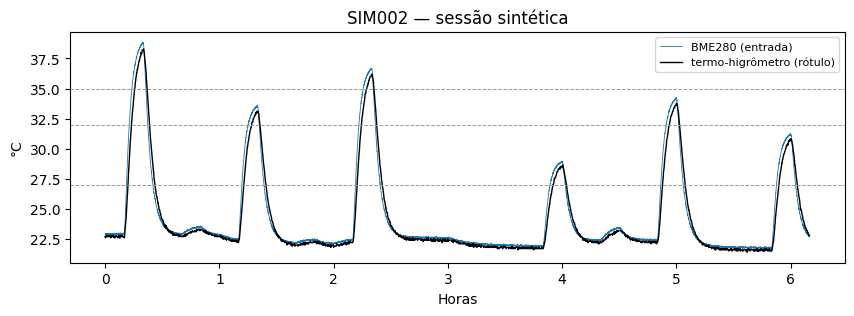

In [8]:
# 8. Conferência: repetição dos clipes e figura de uma sessão de eventos
for p, b in BANCOS.items():
    print(f"{p:10s} passagens completas pelo banco — normal: {b['normal'].usos}, anômalo: {b['anomalo'].usos}, fundo: {b['fundo'].usos}")
a = pd.read_csv(f"{SAIDA}/SIM002/AMB.CSV"); t = pd.read_csv(f"{SAIDA}/SIM002/termo.csv")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(a.amostra / FS / 3600, a.temp, lw=0.6, label="BME280 (entrada)")
ax.plot(np.arange(len(t)) * 10 / 3600, t.temp_ref, lw=1, color="k", label="termo-higrômetro (rótulo)")
for L in (27, 32, 35): ax.axhline(L, color="0.6", ls="--", lw=0.7)
ax.set_xlabel("Horas"); ax.set_ylabel("°C"); ax.legend(fontsize=8); ax.set_title("SIM002 — sessão sintética")
plt.savefig(f"{SAIDA}/conferencia_SIM002.png", dpi=150); plt.show()

## Próximos passos

Nos notebooks 08 a 12, troque na célula 1 `CONJUNTO = "coleta"` por `CONJUNTO = "coleta_sim"`. Ordem: 08 (cada sessão, `LINHA_DE_BASE = True` só na SIM001) → 09 (SIM001) → 10 → 11 → 12. Os modelos vão para `modelos/sim/` e os resultados para `resultados_sim/`, separados dos da coleta real.